In [15]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

df = pd.read_csv('data/Dry_Eye_Dataset.csv')
df.shape

(20000, 26)

In [16]:
# tidy column names: lowercase with underscores
df.columns = (df.columns.str.lower()
              .str.replace('/', '_', regex=False)
              .str.replace('-', '_', regex=False)
              .str.replace(' ', '_', regex=False))

# blood pressure "137/89" -> two numeric columns
df[['systolic', 'diastolic']] = df['blood_pressure'].str.split('/', expand=True).astype(int)
df = df.drop(columns='blood_pressure')

# Y/N columns (including the target) -> 1/0
yn_cols = [c for c in df.columns if set(df[c].unique()) <= {'Y', 'N'}]
for c in yn_cols:
    df[c] = (df[c] == 'Y').astype(int)

df['gender'] = df['gender'].str.lower()
df['gender_m'] = (df['gender'] == 'm').astype(int)

df.head()

,gender,age,sleep_duration,sleep_quality,stress_level,heart_rate,daily_steps,physical_activity,height,weight,...,smart_device_before_bed,average_screen_time,blue_light_filter,discomfort_eye_strain,redness_in_eye,itchiness_irritation_in_eye,dry_eye_disease,systolic,diastolic,gender_m
0,f,24,9.5,2,1,67,3000,31,161,69,...,0,8.7,0,1,1,0,1,137,89,0
1,m,39,9.6,2,3,60,12000,74,164,87,...,0,9.6,1,0,0,1,1,108,64,1
2,f,45,5.4,1,5,95,12000,93,179,94,...,1,4.0,0,1,0,0,0,134,81,0
3,f,45,5.4,4,5,78,19000,32,160,77,...,0,7.6,0,1,0,1,0,110,90,0
4,f,42,5.7,3,2,72,4000,173,179,99,...,0,3.5,0,1,1,0,1,99,67,0


In [17]:
print('shape:', df.shape)
print('missing values:', df.isnull().sum().sum(), '| duplicate rows:', df.duplicated().sum())
df.describe().round(1).T

shape: (20000, 28)
missing values: 0 | duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,20000.0,31.4,8.1,18.0,24.0,31.0,39.0,45.0
sleep_duration,20000.0,7.0,1.7,4.0,5.5,7.0,8.5,10.0
sleep_quality,20000.0,3.0,1.4,1.0,2.0,3.0,4.0,5.0
stress_level,20000.0,3.0,1.4,1.0,2.0,3.0,4.0,5.0
heart_rate,20000.0,79.9,11.8,60.0,70.0,80.0,90.0,100.0
daily_steps,20000.0,10536.9,5752.7,1000.0,6000.0,11000.0,16000.0,20000.0
physical_activity,20000.0,90.1,52.3,0.0,45.0,91.0,135.0,180.0
height,20000.0,174.9,14.7,150.0,162.0,175.0,188.0,200.0
weight,20000.0,74.9,14.7,50.0,62.0,75.0,88.0,100.0
sleep_disorder,20000.0,0.5,0.5,0.0,0.0,0.0,1.0,1.0


dry_eye_disease
1    0.652
0    0.348
Name: proportion, dtype: float64


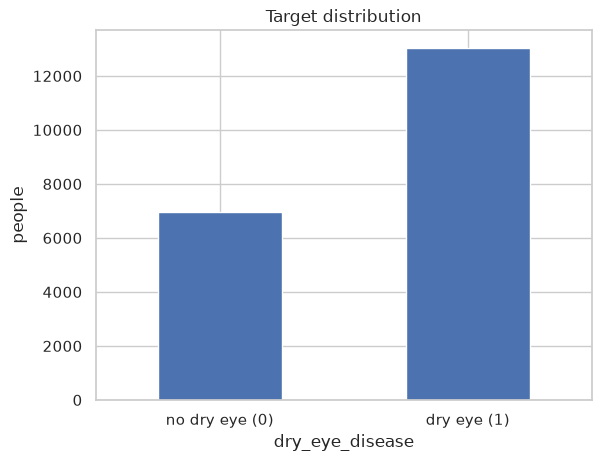

In [18]:
target = 'dry_eye_disease'
print(df[target].value_counts(normalize=True).round(3))

ax = df[target].value_counts().sort_index().plot(kind='bar', rot=0)
ax.set_xticklabels(['no dry eye (0)', 'dry eye (1)'])
ax.set_ylabel('people')
ax.set_title('Target distribution')
plt.show()

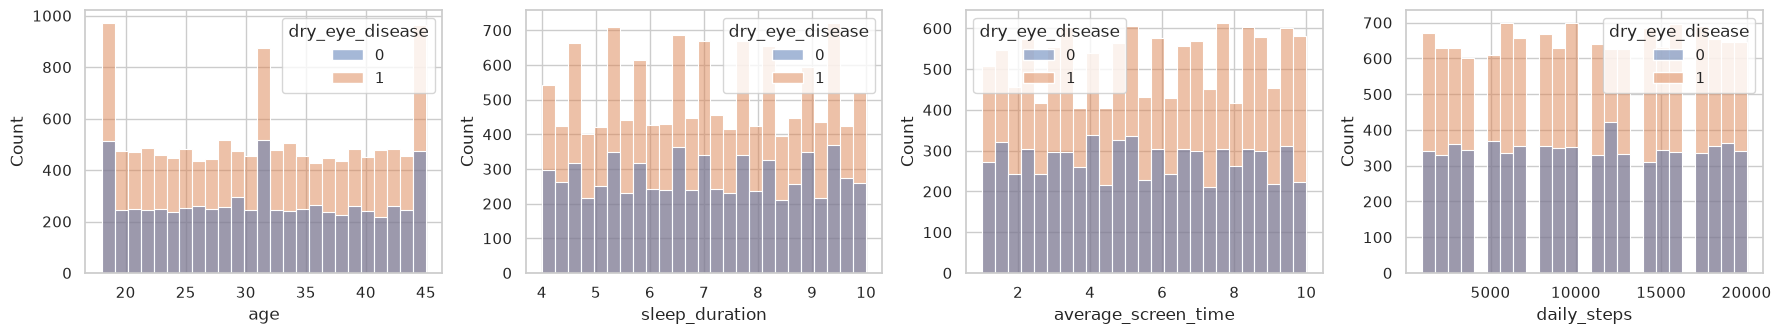

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, ['age', 'sleep_duration', 'average_screen_time', 'daily_steps']):
    sns.histplot(df, x=col, hue=target, bins=25, ax=ax)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
print(len(df_train), len(df_val), len(df_test))

symptoms = ['discomfort_eye_strain', 'redness_in_eye', 'itchiness_irritation_in_eye']
all_features = [c for c in df.columns if c not in ['gender', target]]
lifestyle = [c for c in all_features if c not in symptoms]
print(len(all_features), 'features;', len(lifestyle), 'lifestyle features;', len(symptoms), 'symptoms')

12000 4000 4000
26 features; 23 lifestyle features; 3 symptoms


In [21]:
corr = (df_full_train[all_features].corrwith(df_full_train[target])
        .sort_values(key=abs, ascending=False))
corr.head(10).round(3)

discomfort_eye_strain          0.111
redness_in_eye                 0.109
itchiness_irritation_in_eye    0.100
gender_m                      -0.020
average_screen_time            0.016
smart_device_before_bed       -0.016
diastolic                     -0.014
alcohol_consumption            0.013
ongoing_medication            -0.008
smoking                       -0.007
dtype: float64

In [22]:
from sklearn.metrics import mutual_info_score

mi = {c: mutual_info_score(df_full_train[c], df_full_train[target])
      for c in all_features if df_full_train[c].nunique() <= 6}
pd.Series(mi).sort_values(ascending=False).head(10).round(4)

discomfort_eye_strain          0.0062
redness_in_eye                 0.0059
itchiness_irritation_in_eye    0.0051
gender_m                       0.0002
smart_device_before_bed        0.0001
alcohol_consumption            0.0001
sleep_quality                  0.0001
stress_level                   0.0001
ongoing_medication             0.0000
smoking                        0.0000
dtype: float64

In [23]:
# disease rate by symptom combination
rates = (df_full_train.groupby(symptoms)[target].agg(['mean', 'count']).round(3))
rates

mean  count
discomfort_eye_strain redness_in_eye itchiness_irritation_in_eye              
0                     0              0                            0.313   2024
                                     1                            0.683   1989
                      1              0                            0.701   1994
                                     1                            0.702   2023
1                     0              0                            0.697   2042
                                     1                            0.709   2008
                      1              0                            0.708   1992
                                     1                            0.705   1928

In [24]:
df_full_train = df_full_train.copy()
df_full_train['any_symptom'] = (df_full_train[symptoms].sum(axis=1) > 0).astype(int)
df_full_train.groupby('any_symptom')[target].agg(['mean', 'count']).round(3)

,mean,count
any_symptom,,
0,0.313,2024
1,0.701,13976


In [25]:
from itertools import product
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv = KFold(n_splits=5, shuffle=True, random_state=1)
y_full = df_full_train[target]


def cv_auc(model, cols):
    scores = cross_val_score(model, df_full_train[cols], y_full,
                             cv=cv, scoring='roc_auc', n_jobs=-1)
    return scores.mean(), scores.std()


feature_sets = {'all': all_features, 'symptoms_only': symptoms, 'lifestyle_only': lifestyle}
results = []

for fs_name, cols in feature_sets.items():
    for C in [0.01, 0.1, 1, 10]:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
        results.append((fs_name, 'logreg', f'C={C}', *cv_auc(model, cols)))

    for depth, leaf in product([2, 3, 4, 6], [10, 50, 100]):
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        results.append((fs_name, 'tree', f'depth={depth},leaf={leaf}', *cv_auc(model, cols)))

    for n, depth, leaf in product([100, 200], [3, 5, 8], [10, 50]):
        model = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_leaf=leaf,
                                       random_state=1, n_jobs=1)
        results.append((fs_name, 'forest', f'n={n},depth={depth},leaf={leaf}', *cv_auc(model, cols)))

    for eta, depth, n in product([0.03, 0.1], [2, 3, 4], [100, 200]):
        model = XGBClassifier(learning_rate=eta, max_depth=depth, n_estimators=n,
                              random_state=1, n_jobs=1, eval_metric='auc')
        results.append((fs_name, 'xgboost', f'eta={eta},depth={depth},n={n}', *cv_auc(model, cols)))

df_results = pd.DataFrame(results, columns=['features', 'model', 'params', 'auc_mean', 'auc_std'])
len(df_results)

120

In [26]:
best = (df_results.sort_values('auc_mean', ascending=False)
        .groupby(['features', 'model']).head(1)
        .sort_values(['features', 'auc_mean'], ascending=[True, False]))
best.round(4)

,features,model,params,auc_mean,auc_std
17,all,forest,"n=100,depth=3,leaf=50",0.6008,0.0160
3,all,logreg,C=10,0.6005,0.0147
29,all,xgboost,"eta=0.03,depth=2,n=200",0.6002,0.0166
15,all,tree,"depth=6,leaf=100",0.5955,0.0178
89,lifestyle_only,tree,"depth=3,leaf=100",0.5071,0.0073
116,lifestyle_only,xgboost,"eta=0.1,depth=3,n=100",0.5027,0.0094
100,lifestyle_only,forest,"n=100,depth=8,leaf=10",0.5025,0.0139
83,lifestyle_only,logreg,C=10,0.5001,0.0104
74,symptoms_only,xgboost,"eta=0.1,depth=2,n=100",0.5988,0.0149
42,symptoms_only,logreg,C=1,0.5980,0.0156


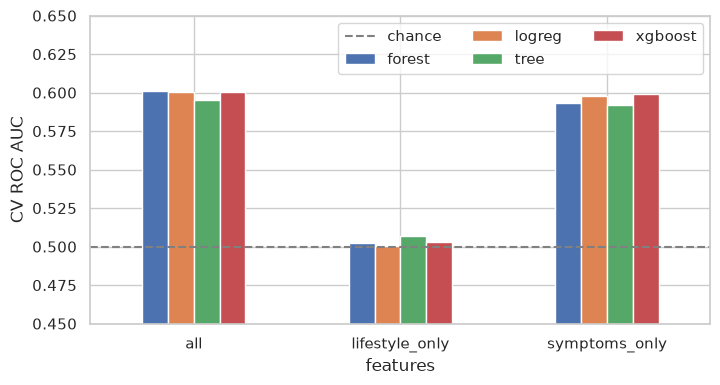

In [27]:
pivot = best.pivot(index='features', columns='model', values='auc_mean')
ax = pivot.plot(kind='bar', rot=0, figsize=(8, 4))
ax.axhline(0.5, color='gray', linestyle='--', label='chance')
ax.set_ylabel('CV ROC AUC')
ax.set_ylim(0.45, 0.65)
ax.legend(loc='upper right', ncol=3)
plt.show()

In [28]:
from sklearn.metrics import roc_auc_score


def add_any_symptom(d):
    d = d.copy()
    d['any_symptom'] = (d[symptoms].sum(axis=1) > 0).astype(int)
    return d


df_train2, df_val2, df_test2 = map(add_any_symptom, [df_train, df_val, df_test])

model = LogisticRegression(C=1.0, max_iter=1000)
model.fit(df_train2[['any_symptom']], df_train2[target])

val_auc = roc_auc_score(df_val2[target], model.predict_proba(df_val2[['any_symptom']])[:, 1])
print(f'validation ROC AUC: {val_auc:.3f}')

validation ROC AUC: 0.589


In [29]:
# compare with the three raw symptoms as separate inputs
model3 = LogisticRegression(C=1.0, max_iter=1000)
model3.fit(df_train2[symptoms], df_train2[target])
val_auc3 = roc_auc_score(df_val2[target], model3.predict_proba(df_val2[symptoms])[:, 1])
print(f'validation ROC AUC with 3 separate symptoms: {val_auc3:.3f}')

print('P(dry eye | no symptom)  =', model.predict_proba(pd.DataFrame({'any_symptom': [0]}))[0, 1].round(3))
print('P(dry eye | any symptom) =', model.predict_proba(pd.DataFrame({'any_symptom': [1]}))[0, 1].round(3))

validation ROC AUC with 3 separate symptoms: 0.596
P(dry eye | no symptom)  = 0.317
P(dry eye | any symptom) = 0.702


In [30]:
# final check, as done in train.py: fit on train + validation, evaluate once on the test set
df_full2 = add_any_symptom(df_full_train.drop(columns='any_symptom'))
final = LogisticRegression(C=1.0, max_iter=1000)
final.fit(df_full2[['any_symptom']], df_full2[target])
test_auc = roc_auc_score(df_test2[target], final.predict_proba(df_test2[['any_symptom']])[:, 1])
print(f'test ROC AUC: {test_auc:.3f}')

test ROC AUC: 0.589
